# Phase 5 — Machine Learning Model Development and Hyperparameter Tuning

This notebook compares three required classifiers using leakage-safe pipelines and the fixed Phase 2 training partition. The business can contact only 20% of customers, so probability ranking, average precision, and fold-local top-20% capture matter more than accuracy alone. The final test partition remains sealed.

## 1. Introduction and business objective

The objective is to rank customers by churn risk while retaining useful positive-class precision and recall. Because churn is the majority class, predicting every customer as churned can produce deceptively high accuracy and recall while offering no useful prioritization. This phase performs model development only; final threshold selection, calibration decisions, held-out evaluation, explainability, and intervention analysis belong to Phase 6.

In [1]:
from pathlib import Path
import hashlib
import json
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.base import clone

CURRENT = Path.cwd().resolve()
ROOT = CURRENT.parent if CURRENT.name == 'notebooks' else CURRENT
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.modeling import (
    CONTACT_FRACTION, MODEL_DISPLAY_NAMES, N_SPLITS, PRIMARY_SCORING,
    RANDOM_STATE, build_model_metadata, build_model_pipeline,
    build_model_pipelines, calculate_top_fraction_metrics,
    evaluate_pipeline_cv, fit_and_save_candidate, generate_oof_probabilities,
    get_baseline_estimators, get_search_iterations, get_search_spaces,
    make_cv_splits, positive_class_probabilities,
    run_hyperparameter_tuning, save_json, summarize_cv_results,
)
from src.preprocessing import (
    IDENTIFIER_COLUMN, TARGET_COLUMN, create_or_load_fixed_split,
    load_and_validate_data, separate_features_target_ids,
)

CLEANED_PATH = ROOT / 'data' / 'processed' / '02_cleaned_dataset.csv'
RAW_PATH = ROOT / 'data' / 'raw' / 'customer_churn_advanced_dataset.csv'
SPLIT_PATH = ROOT / 'data' / 'processed' / '02_split_indices.json'
OOF_PATH = ROOT / 'data' / 'processed' / '05_selected_model_oof_probabilities.csv'
MODEL_PATH = ROOT / 'models' / 'phase5_candidate_model.joblib'
RESULTS_DIR = ROOT / 'reports' / 'modeling'
FIGURE_DIR = ROOT / 'reports' / 'figures'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

BLUE = '#3569D4'
PURPLE = '#8051D6'
LIGHT_BLUE = '#8CB4F5'
LIGHT_PURPLE = '#B9A2EA'
sns.set_theme(style='whitegrid', context='talk')
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')

def save_figure(fig, filename):
    fig.tight_layout()
    path = FIGURE_DIR / filename
    fig.savefig(path, dpi=160, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'Saved: {path.relative_to(ROOT)}')

print(f'scikit-learn version: {sklearn.__version__}')

scikit-learn version: 1.9.1


## 2. Review of preprocessing and engineered features

Every estimator uses the same complete sequence: predictor dataframe → seven deterministic Phase 4 features → numerical median imputation and scaling → categorical missing-value handling and dense one-hot encoding → classifier. Dense output is compatible with `HistGradientBoostingClassifier`. The whole sequence is refitted inside every cross-validation training fold.

## 3. Training dataset overview and split integrity

The notebook stops if the saved artifacts are absent or inconsistent. It selects only the saved training indices and never constructs a final-test feature or target dataframe.

In [2]:
for required in (RAW_PATH, CLEANED_PATH, SPLIT_PATH):
    if not required.is_file():
        raise FileNotFoundError(f'Required previous-phase artifact is missing: {required}')

raw_hash_before = hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()
cleaned_hash_before = hashlib.sha256(CLEANED_PATH.read_bytes()).hexdigest()
split_hash_before = hashlib.sha256(SPLIT_PATH.read_bytes()).hexdigest()
cleaned_df = load_and_validate_data(CLEANED_PATH)
split = create_or_load_fixed_split(cleaned_df, SPLIT_PATH, test_size=0.20, random_state=42)
if not split['loaded_existing']:
    raise RuntimeError('Phase 5 requires the previously saved Phase 2 split.')
train_indices = split['train_indices']
sealed_test_indices = split['test_indices']
train_df = cleaned_df.iloc[train_indices].copy()
X_train, y_train, _ = separate_features_target_ids(train_df)

assert IDENTIFIER_COLUMN not in X_train.columns
assert TARGET_COLUMN not in X_train.columns
assert set(train_indices).isdisjoint(sealed_test_indices)
print(f'Training rows: {len(X_train):,}; original predictors: {X_train.shape[1]}')
print(f'Final-test rows kept sealed: {len(sealed_test_indices):,}')
print(f'Target mapping: 0 = retained, 1 = churned')
print(f'Dataset fingerprint: {split["dataset_fingerprint"]}')

Training rows: 960; original predictors: 18
Final-test rows kept sealed: 240
Target mapping: 0 = retained, 1 = churned
Dataset fingerprint: df788deba598b73abdc3a41b8a1947af63a90c5f369c2a498386a2c0eefeb769


## 4. Target distribution

The training target is majority churn. A prior-probability dummy model provides an essential reference: at the default 0.5 threshold it predicts the majority class for every row, creating high accuracy and recall without meaningful discrimination.

In [3]:
target_summary = y_train.value_counts().sort_index().rename('count').to_frame()
target_summary['percentage'] = target_summary['count'] / len(y_train) * 100
display(target_summary)
print(f'Positive-class prevalence: {y_train.mean():.4%}')

,count,percentage
churn,,
0,131,13.6458
1,829,86.3542


Positive-class prevalence: 86.3542%


## 5. Model selection strategy

The required candidates are Logistic Regression, Random Forest, and Histogram Gradient Boosting. A prior-probability `DummyClassifier` is included only as a naive reference. Average precision (PR-AUC) is the tuning objective because it evaluates probability ranking for the positive class across thresholds. ROC-AUC, threshold-based precision/recall/F1, accuracy, fold variability, and top-20% ranking are retained as complementary evidence.

## 6. Stratified cross-validation

All comparisons use the same five `StratifiedKFold` partitions with shuffling and random state 42. Stratification preserves the unusual majority-churn distribution in every validation fold, while repeated validation across five folds reduces dependence on one arbitrary split.

In [4]:
cv_splits = make_cv_splits(X_train, y_train)
fold_balance = []
for fold, (fit_positions, validation_positions) in enumerate(cv_splits, start=1):
    fold_balance.append({
        'fold': fold, 'fit_rows': len(fit_positions),
        'validation_rows': len(validation_positions),
        'validation_churn_rate': y_train.iloc[validation_positions].mean(),
    })
display(pd.DataFrame(fold_balance))

,fold,fit_rows,validation_rows,validation_churn_rate
0,1,768,192,0.8646
1,2,768,192,0.8646
2,3,768,192,0.8646
3,4,768,192,0.8646
4,5,768,192,0.8594


## 7. Baseline models

Each baseline uses reasonable untuned parameters and the identical fold list. Precision, recall, F1, and accuracy use the estimator's default 0.5 decision threshold; Phase 6 will choose any final operating threshold. Ranking metrics use probabilities.

In [5]:
baseline_summaries = []
fold_frames = []
baseline_pipelines = build_model_pipelines(include_dummy=True)
for model_key, pipeline in baseline_pipelines.items():
    print(f'Evaluating baseline: {MODEL_DISPLAY_NAMES[model_key]}')
    folds = evaluate_pipeline_cv(pipeline, X_train, y_train, cv_splits)
    folds.insert(0, 'stage', 'Naive reference' if model_key == 'dummy' else 'Baseline')
    folds.insert(0, 'model', MODEL_DISPLAY_NAMES[model_key])
    folds.insert(0, 'model_key', model_key)
    fold_frames.append(folds)
    baseline_summaries.append(summarize_cv_results(
        folds, model_key=model_key,
        stage='Naive reference' if model_key == 'dummy' else 'Baseline',
        selected_parameters=baseline_pipelines[model_key].named_steps['model'].get_params(),
    ))
baseline_comparison = pd.DataFrame(baseline_summaries)
display(baseline_comparison[[
    'model', 'stage', 'mean_precision', 'mean_recall', 'mean_f1',
    'mean_roc_auc', 'mean_pr_auc', 'std_pr_auc', 'mean_accuracy',
    'mean_precision_at_20', 'mean_recall_at_20', 'mean_lift_at_20',
]])

Evaluating baseline: Naive Prior Baseline


Evaluating baseline: Logistic Regression


Evaluating baseline: Random Forest


Evaluating baseline: Histogram Gradient Boosting


,model,stage,mean_precision,mean_recall,mean_f1,mean_roc_auc,mean_pr_auc,std_pr_auc,mean_accuracy,mean_precision_at_20,mean_recall_at_20,mean_lift_at_20
0,Naive Prior Baseline,Naive reference,0.8635,1.0000,0.9268,0.5000,0.8635,0.0023,0.8635,0.8718,0.2051,1.0096
1,Logistic Regression,Baseline,0.9028,0.9614,0.9311,0.8653,0.9711,0.0151,0.8771,0.9846,0.2316,1.1402
2,Random Forest,Baseline,0.8837,0.9891,0.9334,0.8575,0.9706,0.0104,0.8781,0.9897,0.2328,1.1462
3,Histogram Gradient Boosting,Baseline,0.9082,0.9650,0.9357,0.8606,0.9699,0.0070,0.8854,0.9795,0.2304,1.1343


The dummy model's PR-AUC should be close to the 86.35% prevalence and its ROC-AUC should be 0.5. Its tied probabilities are ranked with a stable sort, retaining original validation-fold order. This creates a deterministic sample but not a useful risk ranking.

## 8. Hyperparameter tuning

Each required model receives 16 reproducible randomized configurations and the same five folds. The search refits the best configuration on all 960 training rows using average precision as the primary metric. Logistic L1/L2 choices use scikit-learn 1.9's supported `l1_ratio=1/0` equivalents because the older `penalty` argument is deprecated. No unsupported combinations are sampled.

In [6]:
search_spaces = get_search_spaces()
search_iterations = get_search_iterations()
searches = {}
tuning_candidate_frames = []
tuning_summary = {}
for model_key in ('logistic_regression', 'random_forest', 'hist_gradient_boosting'):
    print()
    print(f'Tuning {MODEL_DISPLAY_NAMES[model_key]}: {search_iterations[model_key]} configurations × {N_SPLITS} folds')
    search, candidates, elapsed = run_hyperparameter_tuning(
        model_key, X_train, y_train, cv_splits, n_jobs=1
    )
    searches[model_key] = search
    candidates.insert(0, 'model_key', model_key)
    tuning_candidate_frames.append(candidates)
    tuning_summary[model_key] = {
        'model': MODEL_DISPLAY_NAMES[model_key],
        'tested_configurations': search_iterations[model_key],
        'cv_folds': N_SPLITS,
        'primary_scoring': PRIMARY_SCORING,
        'best_cv_average_precision': search.best_score_,
        'best_parameters': search.best_params_,
        'elapsed_seconds': elapsed,
    }
    print(f'Best PR-AUC: {search.best_score_:.4f}; elapsed: {elapsed:.1f}s')
    print(f'Best parameters: {search.best_params_}')
display(pd.DataFrame(tuning_summary).T)


Tuning Logistic Regression: 16 configurations × 5 folds


Best PR-AUC: 0.9752; elapsed: 8.2s
Best parameters: {'model__l1_ratio': 1.0, 'model__class_weight': None, 'model__C': 0.1}

Tuning Random Forest: 16 configurations × 5 folds


Best PR-AUC: 0.9782; elapsed: 67.3s
Best parameters: {'model__n_estimators': 400, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_features': 0.5, 'model__max_depth': None, 'model__class_weight': 'balanced'}

Tuning Histogram Gradient Boosting: 16 configurations × 5 folds


Best PR-AUC: 0.9741; elapsed: 61.6s
Best parameters: {'model__min_samples_leaf': 10, 'model__max_leaf_nodes': 31, 'model__max_iter': 80, 'model__max_depth': None, 'model__learning_rate': 0.03, 'model__l2_regularization': 0.1, 'model__class_weight': None}


,model,tested_configurations,cv_folds,primary_scoring,best_cv_average_precision,best_parameters,elapsed_seconds
logistic_regression,Logistic Regression,16,5,average_precision,0.9752,"{'model__l1_ratio': 1.0, 'model__class_weight'...",8.2022
random_forest,Random Forest,16,5,average_precision,0.9782,"{'model__n_estimators': 400, 'model__min_sampl...",67.3383
hist_gradient_boosting,Histogram Gradient Boosting,16,5,average_precision,0.9741,"{'model__min_samples_leaf': 10, 'model__max_le...",61.6298


## 9. Class-weight experiments

Because churn is the majority class, `class_weight='balanced'` increases the weight of retained customers rather than churners. This can reduce positive-class recall at the 0.5 threshold while potentially changing precision or ranking. Both unweighted and balanced versions are measured; no assumption is made that balancing must help.

In [7]:
class_weight_rows = []
for model_key in ('logistic_regression', 'random_forest', 'hist_gradient_boosting'):
    for class_weight in (None, 'balanced'):
        estimator = get_baseline_estimators()[model_key].set_params(class_weight=class_weight)
        folds = evaluate_pipeline_cv(build_model_pipeline(estimator), X_train, y_train, cv_splits)
        row = summarize_cv_results(
            folds, model_key=model_key, stage=f'class_weight={class_weight}',
            selected_parameters={'class_weight': class_weight},
        )
        row['class_weight'] = 'None' if class_weight is None else class_weight
        class_weight_rows.append(row)
class_weight_comparison = pd.DataFrame(class_weight_rows)
display(class_weight_comparison[[
    'model', 'class_weight', 'mean_precision', 'mean_recall', 'mean_f1',
    'mean_roc_auc', 'mean_pr_auc', 'mean_precision_at_20', 'mean_recall_at_20',
]])

,model,class_weight,mean_precision,mean_recall,mean_f1,mean_roc_auc,mean_pr_auc,mean_precision_at_20,mean_recall_at_20
0,Logistic Regression,None,0.9028,0.9614,0.9311,0.8653,0.9711,0.9846,0.2316
1,Logistic Regression,balanced,0.9579,0.7914,0.8663,0.8654,0.9709,0.9795,0.2304
2,Random Forest,None,0.8837,0.9891,0.9334,0.8575,0.9706,0.9897,0.2328
3,Random Forest,balanced,0.9193,0.9433,0.9309,0.8701,0.9732,0.9846,0.2316
4,Histogram Gradient Boosting,None,0.9082,0.9650,0.9357,0.8606,0.9699,0.9795,0.2304
5,Histogram Gradient Boosting,balanced,0.9174,0.9349,0.9259,0.8636,0.9686,0.9795,0.2304


## 10. Baseline versus tuned comparison

In [8]:
tuned_summaries = []
for model_key, search in searches.items():
    folds = evaluate_pipeline_cv(search.best_estimator_, X_train, y_train, cv_splits)
    folds.insert(0, 'stage', 'Tuned')
    folds.insert(0, 'model', MODEL_DISPLAY_NAMES[model_key])
    folds.insert(0, 'model_key', model_key)
    fold_frames.append(folds)
    tuned_summaries.append(summarize_cv_results(
        folds, model_key=model_key, stage='Tuned',
        selected_parameters=search.best_params_,
    ))
tuned_comparison = pd.DataFrame(tuned_summaries)
comparison = pd.concat([baseline_comparison, tuned_comparison], ignore_index=True)
stage_order = {'Naive reference': 0, 'Baseline': 1, 'Tuned': 2}
model_order = {'dummy': 0, 'logistic_regression': 1, 'random_forest': 2, 'hist_gradient_boosting': 3}
comparison['_model_order'] = comparison['model_key'].map(model_order)
comparison['_stage_order'] = comparison['stage'].map(stage_order)
comparison = comparison.sort_values(['_model_order', '_stage_order']).drop(columns=['_model_order', '_stage_order']).reset_index(drop=True)
all_fold_results = pd.concat(fold_frames, ignore_index=True)
display(comparison[[
    'model', 'stage', 'mean_precision', 'mean_recall', 'mean_f1',
    'mean_roc_auc', 'mean_pr_auc', 'std_pr_auc', 'mean_accuracy',
    'mean_precision_at_20', 'mean_recall_at_20', 'mean_lift_at_20',
]])

,model,stage,mean_precision,mean_recall,mean_f1,mean_roc_auc,mean_pr_auc,std_pr_auc,mean_accuracy,mean_precision_at_20,mean_recall_at_20,mean_lift_at_20
0,Naive Prior Baseline,Naive reference,0.8635,1.0000,0.9268,0.5000,0.8635,0.0023,0.8635,0.8718,0.2051,1.0096
1,Logistic Regression,Baseline,0.9028,0.9614,0.9311,0.8653,0.9711,0.0151,0.8771,0.9846,0.2316,1.1402
2,Logistic Regression,Tuned,0.8890,0.9843,0.9342,0.8816,0.9752,0.0151,0.8802,0.9897,0.2328,1.1462
3,Random Forest,Baseline,0.8837,0.9891,0.9334,0.8575,0.9706,0.0104,0.8781,0.9897,0.2328,1.1462
4,Random Forest,Tuned,0.9451,0.8626,0.9014,0.8822,0.9782,0.0060,0.8375,0.9949,0.2340,1.1521
5,Histogram Gradient Boosting,Baseline,0.9082,0.9650,0.9357,0.8606,0.9699,0.0070,0.8854,0.9795,0.2304,1.1343
6,Histogram Gradient Boosting,Tuned,0.8969,0.9638,0.9291,0.8715,0.9741,0.0054,0.8729,0.9949,0.2340,1.1521


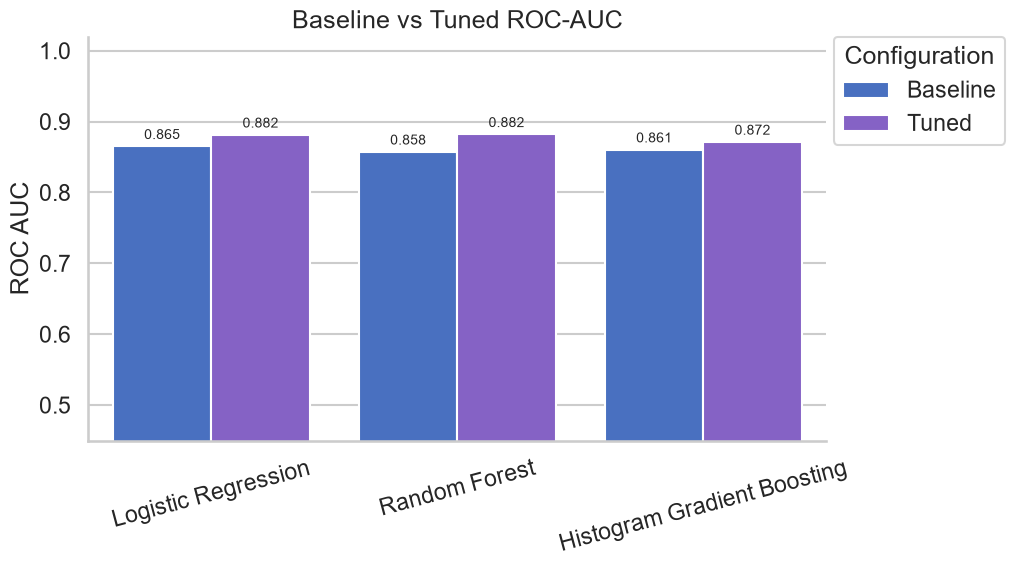

Saved: reports\figures\m5_01_roc_auc_comparison.png


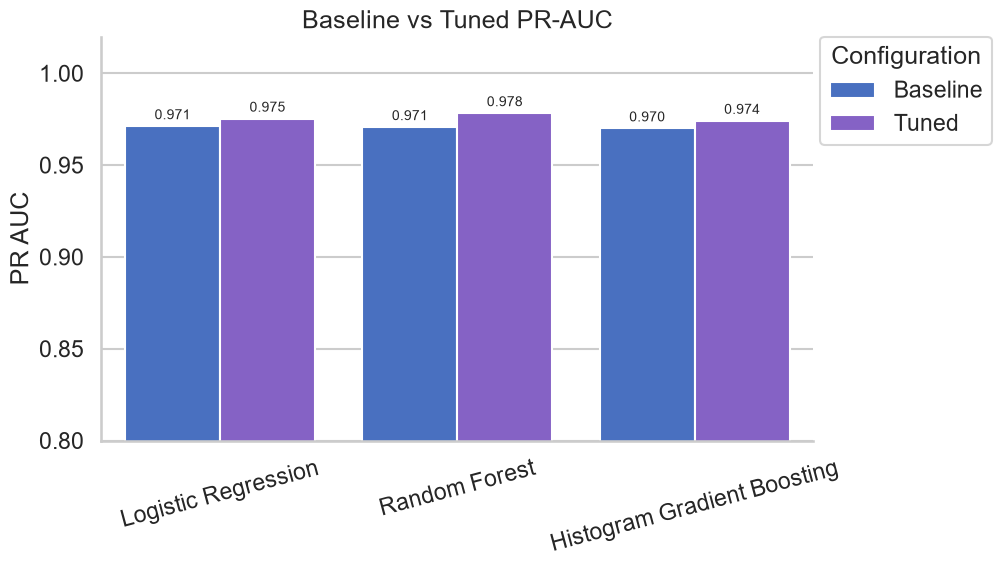

Saved: reports\figures\m5_02_pr_auc_comparison.png


In [9]:
plot_data = comparison[comparison['model_key'] != 'dummy'].copy()
for metric, title, filename, lower in [
    ('mean_roc_auc', 'Baseline vs Tuned ROC-AUC', 'm5_01_roc_auc_comparison.png', 0.45),
    ('mean_pr_auc', 'Baseline vs Tuned PR-AUC', 'm5_02_pr_auc_comparison.png', 0.80),
]:
    fig, ax = plt.subplots(figsize=(10.5, 6))
    sns.barplot(data=plot_data, x='model', y=metric, hue='stage', palette=[BLUE, PURPLE], ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f', padding=3, fontsize=10)
    ax.set(title=title, xlabel='', ylabel=metric.replace('mean_', '').replace('_', ' ').upper(), ylim=(lower, 1.02))
    ax.tick_params(axis='x', rotation=15)
    ax.legend(title='Configuration', loc='upper left', bbox_to_anchor=(1.01, 1), borderaxespad=0)
    sns.despine(fig=fig)
    save_figure(fig, filename)

### Interpretation

The two AUC measures compare discrimination and positive-class ranking without selecting a final threshold. PR-AUC must be read against the high 0.8635 prevalence baseline. Small differences should be weighed against fold variability and model complexity rather than treated as conclusive.

## 11. Model stability analysis

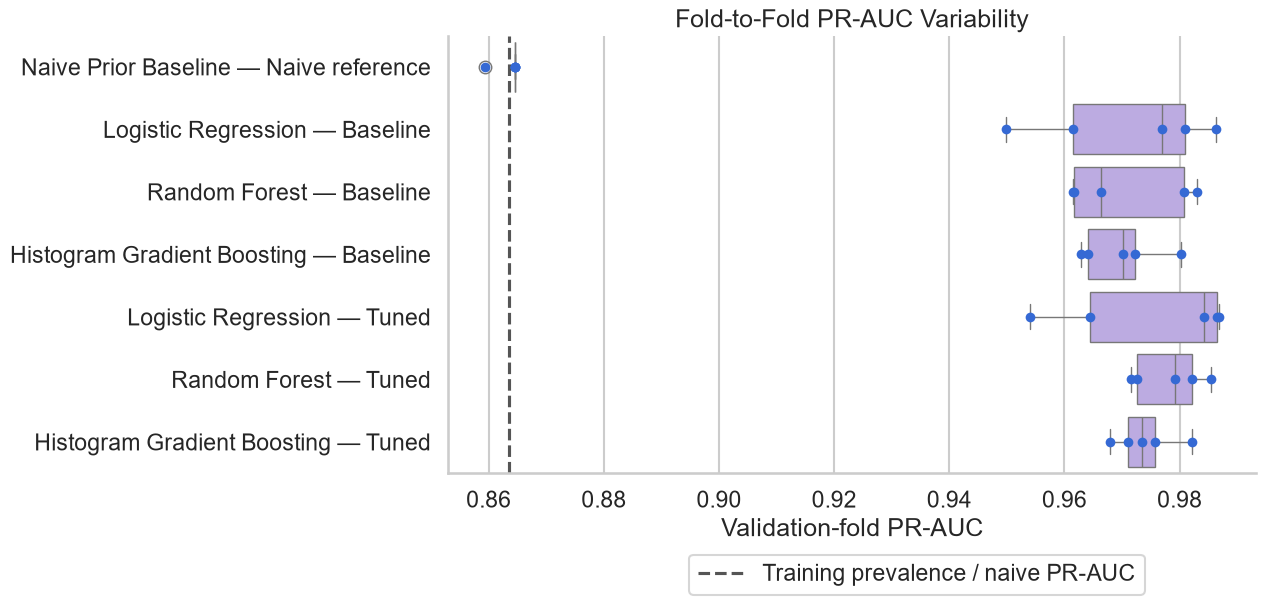

Saved: reports\figures\m5_03_cv_pr_auc_variability.png


In [10]:
all_fold_results['configuration'] = all_fold_results['model'] + ' — ' + all_fold_results['stage']
fig, ax = plt.subplots(figsize=(13, 6.5))
sns.boxplot(data=all_fold_results, y='configuration', x='pr_auc', color=LIGHT_PURPLE, ax=ax)
sns.stripplot(data=all_fold_results, y='configuration', x='pr_auc', color=BLUE, size=7, jitter=False, ax=ax)
ax.axvline(y_train.mean(), color='#555555', linestyle='--', label='Training prevalence / naive PR-AUC')
ax.set(title='Fold-to-Fold PR-AUC Variability', xlabel='Validation-fold PR-AUC', ylabel='')
ax.legend(loc='upper center', bbox_to_anchor=(0.58, -0.16))
sns.despine(ax=ax)
save_figure(fig, 'm5_03_cv_pr_auc_variability.png')

### Interpretation

Each point is one validation fold and each box summarizes five folds. Narrower spreads indicate greater stability. The dashed prevalence line is the expected PR-AUC of a non-informative prior ranking; performance above it must still be confirmed on the untouched final test set.

## 12. Training-only top-20% risk-ranking comparison

Within each validation fold, customers are sorted by positive-class probability. The contact count is `ceil(0.20 × validation rows)`. Equal probabilities retain original fold order through stable sorting. Precision@20% is the churn fraction among contacted customers; recall@20% is the fraction of all validation churners captured. Lift divides precision@20% by fold prevalence. Finding a churner does not prove that contacting them will prevent churn.

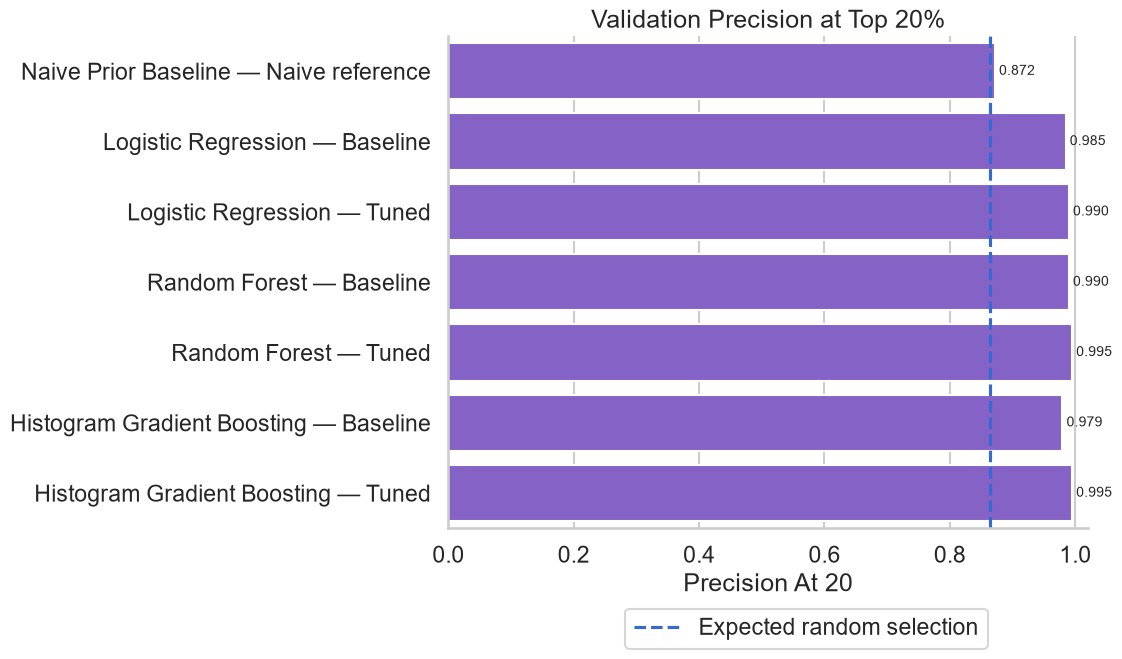

Saved: reports\figures\m5_04_top20_precision.png


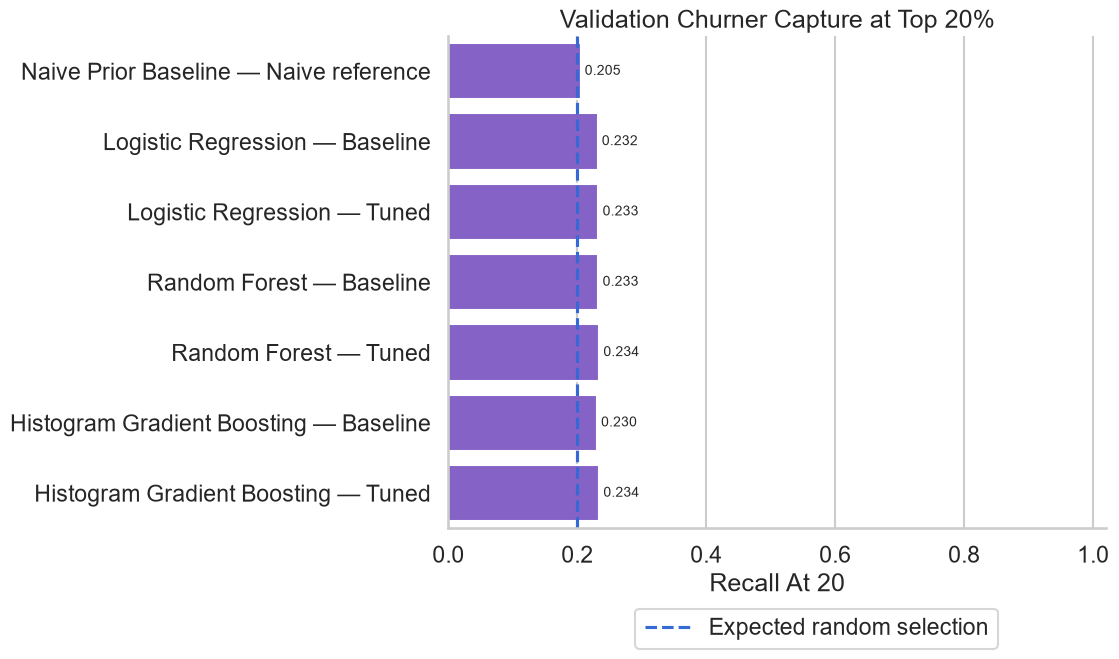

Saved: reports\figures\m5_05_top20_capture.png


In [11]:
ranking_plot = comparison.copy()
ranking_plot['configuration'] = ranking_plot['model'] + ' — ' + ranking_plot['stage']
for metric, title, baseline, filename in [
    ('mean_precision_at_20', 'Validation Precision at Top 20%', y_train.mean(), 'm5_04_top20_precision.png'),
    ('mean_recall_at_20', 'Validation Churner Capture at Top 20%', CONTACT_FRACTION, 'm5_05_top20_capture.png'),
]:
    fig, ax = plt.subplots(figsize=(11.5, 7))
    sns.barplot(data=ranking_plot, y='configuration', x=metric, color=PURPLE, ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f', padding=3, fontsize=10)
    ax.axvline(baseline, color=BLUE, linestyle='--', label='Expected random selection')
    ax.set(title=title, xlabel=metric.replace('mean_', '').replace('_', ' ').title(), ylabel='', xlim=(0, 1.02))
    ax.legend(loc='upper center', bbox_to_anchor=(0.56, -0.14))
    sns.despine(fig=fig)
    save_figure(fig, filename)

### Interpretation

The dashed lines show the expected random-selection baselines: precision approximately equals churn prevalence, while expected capture is approximately the contacted fraction. Because churn prevalence is already high, precision has limited headroom; capture rate and lift provide necessary context.

## 13. Provisional model selection

The provisional winner is the tuned model with the highest mean five-fold PR-AUC. ROC-AUC, top-20% ranking, fold variability, complexity, and runtime are then reviewed as secondary considerations. This is a development-time selection, not a final performance claim.

In [12]:
selected_row = tuned_comparison.sort_values(
    ['mean_pr_auc', 'mean_precision_at_20', 'mean_roc_auc'],
    ascending=False, kind='stable',
).iloc[0]
selected_key = selected_row['model_key']
selected_pipeline = searches[selected_key].best_estimator_
selected_params = searches[selected_key].best_params_
print(f'Provisional model: {MODEL_DISPLAY_NAMES[selected_key]}')
print(f'Best parameters: {selected_params}')
display(selected_row.to_frame('selected_value'))

Provisional model: Random Forest
Best parameters: {'model__n_estimators': 400, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_features': 0.5, 'model__max_depth': None, 'model__class_weight': 'balanced'}


,selected_value
model_key,random_forest
model,Random Forest
stage,Tuned
mean_precision,0.9451
std_precision,0.0172
mean_recall,0.8626
std_recall,0.0340
mean_f1,0.9014
std_f1,0.0144
mean_roc_auc,0.8822


## 14. Out-of-fold probabilities and provisional artifact

Each saved probability is generated by a fold model that excluded that row. The file contains only dataset row positions, fold numbers, and probabilities—no customer identifiers or labels—and is stored under ignored processed data. Because hyperparameters were selected using these training data, the OOF estimates can retain model-selection optimism.

In [13]:
oof_results = generate_oof_probabilities(selected_pipeline, X_train, y_train, cv_splits)
OOF_PATH.parent.mkdir(parents=True, exist_ok=True)
oof_results.to_csv(OOF_PATH, index=False)
oof_ranking = calculate_top_fraction_metrics(
    y_train.to_numpy(), oof_results['oof_churn_probability'].to_numpy()
)
display(pd.Series(oof_ranking, name='training_OOF'))
print(f'OOF output: {OOF_PATH.relative_to(ROOT)} ({len(oof_results):,} rows)')

fitted_candidate = fit_and_save_candidate(
    selected_pipeline, X_train, y_train, MODEL_PATH
)
loaded_candidate = joblib.load(MODEL_PATH)
np.testing.assert_allclose(
    positive_class_probabilities(fitted_candidate, X_train.iloc[:25]),
    positive_class_probabilities(loaded_candidate, X_train.iloc[:25]),
)
print(f'Candidate artifact verified: {MODEL_PATH.relative_to(ROOT)}')

contact_count               192.0000
true_positives_contacted    191.0000
precision_at_20               0.9948
recall_at_20                  0.2304
prevalence                    0.8635
random_precision_baseline     0.8635
random_recall_baseline        0.2000
lift_at_20                    1.1520
Name: training_OOF, dtype: float64

OOF output: data\processed\05_selected_model_oof_probabilities.csv (960 rows)


Candidate artifact verified: models\phase5_candidate_model.joblib


## 15. Save aggregate development results

In [14]:
comparison.to_csv(RESULTS_DIR / 'phase5_model_comparison.csv', index=False)
all_fold_results.to_csv(RESULTS_DIR / 'phase5_fold_results.csv', index=False)
class_weight_comparison.to_csv(RESULTS_DIR / 'phase5_class_weight_comparison.csv', index=False)
tuning_candidates = pd.concat(tuning_candidate_frames, ignore_index=True)
tuning_candidates.to_csv(RESULTS_DIR / 'phase5_tuning_candidates.csv', index=False)
save_json(tuning_summary, RESULTS_DIR / 'phase5_tuning_summary.json')
metadata = build_model_metadata(
    model_key=selected_key, best_parameters=selected_params,
    dataset_fingerprint=split['dataset_fingerprint'], training_rows=len(X_train),
)
metadata['selected_cv_metrics'] = {
    key: selected_row[key] for key in [
        'mean_precision', 'mean_recall', 'mean_f1', 'mean_roc_auc',
        'mean_pr_auc', 'std_pr_auc', 'mean_accuracy',
        'mean_precision_at_20', 'mean_recall_at_20', 'mean_lift_at_20',
    ]
}
metadata['oof_top20_metrics'] = oof_ranking
metadata['oof_output'] = str(OOF_PATH.relative_to(ROOT))
metadata['model_artifact'] = str(MODEL_PATH.relative_to(ROOT))
save_json(metadata, RESULTS_DIR / 'phase5_model_metadata.json')
print('Saved aggregate CSV/JSON results under reports/modeling/.')

Saved aggregate CSV/JSON results under reports/modeling/.


## 16. Final Phase 5 verification

In [15]:
expected_figures = [
    'm5_01_roc_auc_comparison.png',
    'm5_02_pr_auc_comparison.png',
    'm5_03_cv_pr_auc_variability.png',
    'm5_04_top20_precision.png',
    'm5_05_top20_capture.png',
]
expected_results = [
    'phase5_model_comparison.csv', 'phase5_fold_results.csv',
    'phase5_class_weight_comparison.csv', 'phase5_tuning_candidates.csv',
    'phase5_tuning_summary.json', 'phase5_model_metadata.json',
]
assert all((FIGURE_DIR / name).is_file() for name in expected_figures)
assert all((RESULTS_DIR / name).is_file() for name in expected_results)
assert MODEL_PATH.is_file() and OOF_PATH.is_file()
assert len(oof_results) == len(X_train) and oof_results['dataset_row_index'].is_unique
assert hashlib.sha256(RAW_PATH.read_bytes()).hexdigest() == raw_hash_before
assert hashlib.sha256(CLEANED_PATH.read_bytes()).hexdigest() == cleaned_hash_before
assert hashlib.sha256(SPLIT_PATH.read_bytes()).hexdigest() == split_hash_before
assert split['loaded_existing'] and len(sealed_test_indices) == 240
assert set(comparison['model_key']) == {
    'dummy', 'logistic_regression', 'random_forest', 'hist_gradient_boosting'
}
assert (comparison['stage'] == 'Tuned').sum() == 3

print('Required ML models trained: 3')
print('Baseline/tuned comparison rows: 7')
print(f'Figures verified: {len(expected_figures)}')
print('Raw dataset, cleaned dataset, and saved split unchanged: True')
print('Final-test features, labels, predictions, and metrics inspected: 0')
print('Final threshold selected: No')

Required ML models trained: 3
Baseline/tuned comparison rows: 7
Figures verified: 5
Raw dataset, cleaned dataset, and saved split unchanged: True
Final-test features, labels, predictions, and metrics inspected: 0
Final threshold selected: No


## 17. Summary and limitations

Phase 5 produces reproducible training-only comparisons, tuned pipelines, fold-level stability evidence, top-20% ranking metrics, a provisional candidate fitted on all training rows, and OOF probabilities for Phase 6. Accuracy is retained only as a supplementary measure.

The tuned comparisons and selected OOF estimates are not nested-CV estimates and may contain model-selection optimism. Source-field timing remains unresolved, class 1 is unusually prevalent, and probability calibration has not been assessed. The final test set has not been evaluated. Phase 6 must examine calibration and thresholds using training/OOF evidence before one-time final evaluation on the sealed test partition.